# 04. Обучение артефактов и история экспериментов

Судья не переобучает модели оффлайн: `solution/artifacts/` содержит предобученные пулы, а внутри
сессии модели дообучаются онлайн в `fit_block` по завершённым блокам. Здесь — что лежит в
артефактах, чем и на чём они обучены, и как менялся балл по ходу работы.

In [1]:
import os, sys, json, time, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "assets":
    ROOT = ROOT.parent
SOL = ROOT / "solution"
sys.path.insert(0, str(SOL))
# каталог с сессиями *.mat (распакованный data.zip организаторов: data/Data/*.mat);
# переопределяется переменной окружения HORMIGAS_DATA
DATA = Path(os.environ.get("HORMIGAS_DATA", ROOT / "data" / "Data"))
SESSIONS = sorted(p for p in DATA.glob("*.mat") if p.name.lower() != "montage.mat")
MONTAGE = next((p for p in (DATA / "Montage.mat", DATA.parent / "Montage.mat") if p.exists()), None)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
CLASS_NAMES = {1: "покой", 2: "левая", 3: "правая"}
print("сессий:", len(SESSIONS), "| Montage.mat:", MONTAGE is not None)

сессий: 56 | Montage.mat: True


## 1. Состав артефактов сдачи

In [2]:
cfg = json.loads((SOL / "artifacts" / "config.json").read_text())
print("ЭЭГ-модель:", cfg["eeg_model"], "→", cfg["eeg"]["guard_inner_model"], "→", cfg["eeg"]["inner_model"])
print("NIRS-модель:", cfg["nirs_model"], "| слияние:", cfg["fusion"])
rows = []
for p in sorted((SOL / "artifacts").iterdir()):
    size = sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size
    rows.append(dict(артефакт=p.name + ("/" if p.is_dir() else ""), файлов=len(list(p.iterdir())) if p.is_dir() else 1,
                     МБ=round(size / 2 ** 20, 2)))
DESC = {
    "config.json": "конфигурация конвейера (модели, гиперпараметры)",
    "eeg_pool.npz": "кросс-субъектная LR на касательном пространстве ковариаций 2 с (все участники)",
    "eeg_subj/": "пулы ЭЭГ по участникам (для знакомого участника — вес 0.3)",
    "eeg_lrnb_pool.npz": "эксперт «узкие полосы» (LR, окно 4 с, сенсомоторные каналы)",
    "eeg_lrsm4_pool.npz": "эксперт «сенсомоторный TS 4 с» (LR)",
    "eeg_lrnb_subj/": "эксперт nb по участникам", "eeg_lrsm4_subj/": "эксперт sm4 по участникам",
    "eeg_dl_0.npz": "FBShallow-сеть, сид 0 (веса для numpy-инференса)", "eeg_dl_1.npz": "FBShallow, сид 1",
    "eeg_dl_2.npz": "FBShallow, сид 2", "eeg_dl_3.npz": "FBShallow, сид 3",
    "nirs_subj/": "пулы NIRS-каскада по участникам",
    "fusion_meta.json": "мета-логрегрессии StackedFusion (гибрид / ЭЭГ-only)",
    "README.txt": "заглушка организаторов"}
t = pd.DataFrame(rows); t["что это"] = t["артефакт"].map(DESC).fillna("")
print("итого, МБ:", round(t["МБ"].sum(), 1))
t

ЭЭГ-модель: artifact_guard:EEGArtifactGuard → eeg_dl:EEGWithDL → eeg_model:EEGLRExperts
NIRS-модель: nirs_model:NirsCascadeEns | слияние: fusion_stacked:StackedFusion
итого, МБ: 2.2


,артефакт,файлов,МБ,что это
0,README.txt,1,0.00,заглушка организаторов
1,config.json,1,0.00,"конфигурация конвейера (модели, гиперпараметры)"
2,eeg_dl_0.npz,1,0.13,"FBShallow-сеть, сид 0 (веса для numpy-инференса)"
3,eeg_dl_1.npz,1,0.13,"FBShallow, сид 1"
4,eeg_dl_2.npz,1,0.13,"FBShallow, сид 2"
5,eeg_dl_3.npz,1,0.13,"FBShallow, сид 3"
6,eeg_lrnb_pool.npz,1,0.01,"эксперт «узкие полосы» (LR, окно 4 с, сенсомот..."
7,eeg_lrnb_subj/,14,0.17,эксперт nb по участникам
8,eeg_lrsm4_pool.npz,1,0.02,эксперт «сенсомоторный TS 4 с» (LR)
9,eeg_lrsm4_subj/,14,0.26,эксперт sm4 по участникам


In [3]:
z = np.load(SOL / "artifacts" / "eeg_pool.npz", allow_pickle=True)
print("eeg_pool.npz:", {k: z[k].shape for k in z.files})
fm = json.loads((SOL / "artifacts" / "fusion_meta.json").read_text())
print("fusion_meta.json: params =", list(fm["params"])[:10], "| models =", list(fm["models"]),
      "| models_subject =", list(fm.get("models_subject") or {}))
print("пулов участников ЭЭГ:", len(list((SOL / "artifacts" / "eeg_subj").iterdir())),
      "| NIRS:", len(list((SOL / "artifacts" / "nirs_subj").iterdir())))

eeg_pool.npz: {'mean': (1617,), 'scale': (1617,), 'coef': (3, 1617), 'intercept': (3,)}
fusion_meta.json: params = ['eeg_taus', 'nirs_taus', 'center_T', 'center_ref_tau', 'post_tau_s', 'post_hier_tau_s', 'bias', 'eeg_bias', 'nirs_prior', 'nirs_tau_s'] | models = ['eeg', 'hyb'] | models_subject = ['eeg', 'hyb']
пулов участников ЭЭГ: 14 | NIRS: 14


## 2. Как обучается каждая часть

| компонент | где учится | на чём | скрипт |
|---|---|---|---|
| within-sLDA ЭЭГ (касательное пространство 7 полос × 2 с, shrinkage 0.8) | онлайн, `fit_block` | завершённые блоки текущей сессии | `solution/eeg_model.py` |
| пул-LR ЭЭГ (`eeg_pool.npz`, `eeg_subj/`) | оффлайн | другие сессии / участники | `src/eeg/final.py`, `src/eeg/build_subjpool.py` |
| эксперты nb / sm4 (окно 4 с) | оффлайн пул + онлайн sLDA | то же | `src/eeg/lr/build_pools.py` |
| FBShallow × 4 сида (numpy-инференс) | оффлайн (GPU) + онлайн sLDA на эмбеддингах | то же | `src/dl/train.py`, `src/dl/build_pools.sh`, `src/dl/np_infer.py` |
| охрана ВЧ-артефактов | без обучения (причинный детектор) | — | `solution/artifact_guard.py` |
| NIRS-каскад (8 sLDA «задача/покой» × 4 sLDA «левая/правая») | онлайн + пул участника | блоки сессии, другие сессии участника | `solution/nirs_model.py`, `src/nirs/build_subjpool.py` |
| StackedFusion (мета-LR по многомасштабным признакам вероятностей) | оффлайн | вероятности dev-прогонов (хронологических/LOSessO/LOSubjO) | `src/fusion/build_meta.py`, `src/fusion/tune.py` |

Полная пересборка (кэши → пулы → dev-прогоны с `--dump-probs` → мета-модели слияния):

```bash
PY=python; SCR=<scratch>
$PY -m src.features.build_cache && $PY -m src.eeg.cache --f64
for cfg in "0.005 0.1 2 bp005_10" "0.01 0.2 2 bp01_20" "0.02 0.3 2 bp02_30" "0.01 0.5 3 bp01_50"; do
  set -- $cfg; $PY -m src.nirs.build_bank --lo $1 --hi $2 --order $3 --tag nirs_bank_$4; done
$PY -m src.eeg.final 2 all 0.8 0.8 ts2s_all $SCR          # пул ЭЭГ + LOSubjO-пулы
$PY -m src.eeg.lr.nbcache 8
$PY -m src.scripts.build_chrono $SCR/tsF64_w2_all.pkl      # хронологические артефакты по сессиям
$PY -m src.eeg.lr.build_pools --only chrono
bash src/dl/build_pools.sh chrono                          # сети (GPU)
$PY solution/tools/dev_run.py --input data/raw/Data --output-dir $SCR/dev/dev_chrono     --loseso-artifacts data/features/chrono --dump-probs --jobs 4
$PY -m src.fusion.build_meta --runs-dir $SCR/dev           # мета-модели слияния
```

Полный список команд (включая LOSessO/LOSubjO) — `report/REPORT.md`, раздел «Воспроизведение»;
по каждому эксперименту — `docs/experiments/*.md`.

## 3. Онлайн-дообучение внутри сессии: вклад пула

Демонстрация на одной сессии: боевая ЭЭГ-модель с пулом и та же модель без пулов (только
within-sLDA по завершённым блокам). Сравниваем ЭЭГ-вероятности на оцениваемых окнах.

In [4]:
import io_utils as iu
from classifier import OnlineClassifier
from score import confusion_from_preds, metrics_block
import shutil

def eeg_only_run(sess, art):
    clf = OnlineClassifier(dict(iu.session_meta(sess), has_nirs=False)); clf.load(art)
    st, bl, n = sess["states"], sess["blocks"], len(sess["states"])
    block_end = {int(b): int(np.flatnonzero(bl == b)[-1]) + 1 for b in np.unique(bl) if b >= 1}
    wins = {e: y for _, e, y in iu.iter_scored_windows(st, bl, sess["fs_eeg"])}
    events = sorted([(e, 0) for e in wins] + [(e, 1) for e in block_end.values()])
    cur, yt, yp = 0, [], []
    for e, kind in events:
        if e > cur:
            clf.push(sess["eeg"][cur:e], (None, None)); cur = e
        if kind == 1:
            b = [k for k, v in block_end.items() if v == e][0]; mask = (bl == b) & (st > 0)
            clf.fit_block(b, {"states": st[mask], "eeg_indices": np.flatnonzero(mask), "block": b})
        else:
            yt.append(wins[e]); yp.append(clf.predict()["y"])
    return metrics_block(confusion_from_preds(np.array(yt), np.array(yp)))

# без пулов: копия артефактов без предобученных файлов (config.json и мета-модель слияния остаются)
nopool = Path(tempfile.mkdtemp(prefix="nopool_"))
for f in ("config.json", "fusion_meta.json"):
    shutil.copy(SOL / "artifacts" / f, nopool / f)
cfg_np = json.loads((nopool / "config.json").read_text())
cfg_np["eeg"]["dl"]["files"] = []
(nopool / "config.json").write_text(json.dumps(cfg_np))
sess = iu.load_session(SESSIONS[-1])
res = {"пулы + дообучение (сдача)": eeg_only_run(sess, SOL / "artifacts"),
       "только дообучение внутри сессии": eeg_only_run(sess, nopool)}
print("сессия", SESSIONS[-1].stem, "(артефакты сдачи видели эту сессию — сравнение иллюстративное)")
pd.DataFrame({k: {"min-F1": v["min_f1"], "macro-recall": v["macro_recall"]} for k, v in res.items()}).T.round(3)

сессия 2026.03.27.16.34.41_N14 (артефакты сдачи видели эту сессию — сравнение иллюстративное)


,min-F1,macro-recall
пулы + дообучение (сдача),0.83,0.877
только дообучение внутри сессии,0.51,0.632


## 4. История балла

Официальная цифра на каждом этапе — хронологический протокол официальным каркасом (кроме
бейзлайна stage0, посчитанного своим каркасом до появления хронологии).

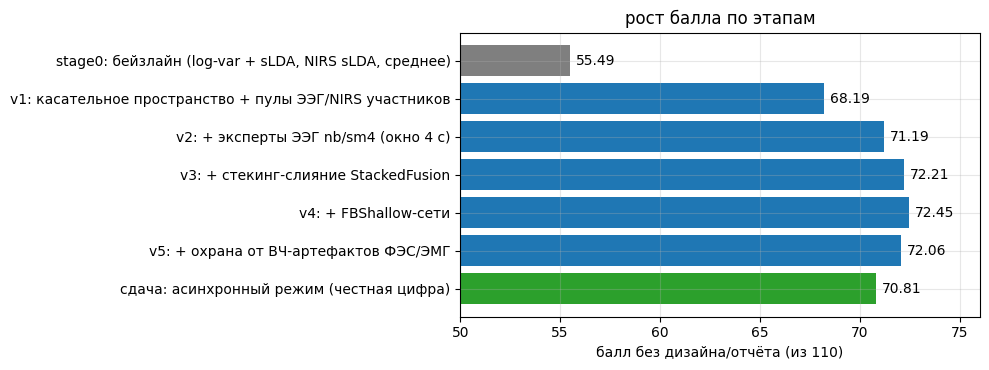

,этап,hyb_minF1,hyb_recall,total
0,"stage0: бейзлайн (log-var + sLDA, NIRS sLDA, с...",0.448,0.593,55.491
1,v1: касательное пространство + пулы ЭЭГ/NIRS у...,0.586,0.714,68.190
2,v2: + эксперты ЭЭГ nb/sm4 (окно 4 с),0.624,0.737,71.195
3,v3: + стекинг-слияние StackedFusion,0.637,0.745,72.208
4,v4: + FBShallow-сети,0.640,0.749,72.454
5,v5: + охрана от ВЧ-артефактов ФЭС/ЭМГ,0.635,0.744,72.058
6,сдача: асинхронный режим (честная цифра),0.621,0.732,70.814


In [5]:
hist = [("stage0: бейзлайн (log-var + sLDA, NIRS sLDA, среднее)", "results/metrics_baseline_stage0"),
        ("v1: касательное пространство + пулы ЭЭГ/NIRS участников", "results/metrics_chrono_v1"),
        ("v2: + эксперты ЭЭГ nb/sm4 (окно 4 с)", "results/metrics_chrono_v2"),
        ("v3: + стекинг-слияние StackedFusion", "results/metrics_chrono_v3"),
        ("v4: + FBShallow-сети", "results/metrics_chrono_v4"),
        ("v5: + охрана от ВЧ-артефактов ФЭС/ЭМГ", "results/metrics_chrono_v5"),
        ("сдача: асинхронный режим (честная цифра)", "results/metrics")]
rows = []
for name, d in hist:
    a = json.loads((ROOT / d / "metrics.json").read_text())
    if "score" in a:
        rows.append(dict(этап=name, hyb_minF1=a["hybrid"]["min_f1"], hyb_recall=a["hybrid"]["macro_recall"], total=a["score"]["total"]))
    else:   # формат stage0
        rows.append(dict(этап=name, hyb_minF1=a["F_global"], hyb_recall=a["P_global"], total=a["points"]["total_without_design"]))
h = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(h.этап[::-1], h.total[::-1], color=["C2"] + ["C0"] * (len(h) - 2) + ["C7"])
for i, v in enumerate(h.total[::-1]):
    ax.text(v + 0.3, i, f"{v:.2f}", va="center")
ax.set_xlim(50, 76); ax.set_xlabel("балл без дизайна/отчёта (из 110)"); ax.set_title("рост балла по этапам")
plt.tight_layout(); plt.show()
h.round(3)

Метки этапов v1–v5 — краткие; подробности и отвергнутые варианты — `report/REPORT.md` §5 и
`docs/experiments/*.md`. Шаги v5 (охрана артефактов, −0.4) и последний (асинхронный режим, −1.2 балла) — сознательная плата за
честность и соответствие правилам: решение не опирается на загрязнённые ФЭС окна, пересчитывается на каждой точке сетки в `push` и не зависит от
расписания вызовов `predict`.